## Pegasus Evaluation: SLO-based Composition Planning

Section C.2. An application type (vision, audio, lidar) has five service compositions: the chains
`b1u-<application>-<i>` of the second campaign. A client of an application states its requirements as SLOs on three
dimensions, and a numerical solver chooses the composition and its configuration that meets them, as in the RASK paper
(SummerSOC, `agent/components/Optimizer_v2.py`). The chosen configurations are then deployed on the testbed; the
deployment table at the end lists them. Implementation: `slo_planning.py` (next to this notebook, outside `pegasus/`,
so that the cached experiments of B.1 to C.1 are not recomputed). C.1: `2e_finetuning.ipynb`.

**Configuration of a composition** with $K$ services:
- $q$, the data quality that every service of the composition processes (knob `data_quality`, shared by all services):
  the image width in pixels for vision, the quality level of the campaign for audio and lidar;
- $w_k \in \{1, \dots, 4\}$, the number of workers of service $k$ (knob `parallelism`);
- $m_k \in \{1, 2\}$, the model size of every detector that has one (knob `model_size`, vision only).

**SLO dimensions**, one number per configuration:
- *cost*: the total number of workers, $\sum_k w_k$;
- *latency*: the Pegasus Node bound (s) on the p95 of the end-to-end latency at the arrival rate $\lambda$ (items/s,
  Poisson arrivals) of the application, with the load-aware models of B.1 (`load_aware_b4.py`). Every service is
  bounded on its own with the violation probability $\varepsilon = \alpha / K$ ($\alpha = 0.05$ for the p95), and the
  end-to-end bound is the sum of the $K$ node bounds;
- *quality*: $q$, and for vision the smallest model size $\min_k m_k$ among the detectors of the composition (a
  composition without a detector has model size 0).

A **scenario** constrains one to three of these dimensions (at most so many workers, at most this p95, at least this
quality) and names one *goal* that the solver optimizes among the configurations that meet the constraints: min cost,
min latency or max quality. Ties of the goal are broken by the other two dimensions with a weight of `TIE_WEIGHT`.
A scenario also names the capabilities it needs (its functional requirement); only compositions that contain a service
for each of them are candidates.

**Training data.** Every service of a composition is trained as in B.1 on its benchmark runs with one to four workers
(`benchmark/w1/` to `benchmark/w4/`), without any run of a chain: a composition is planned as if it had never run.

- **C.2a. Scenarios:** five sets of SLOs per application, one per dimension and two that combine dimensions.
- **C.2b. SLSQP on the continuous relaxation:** the solver of the RASK paper, restarted from random points per composition.
- **C.2c. Exhaustive search (reference):** every grid configuration of every composition.
- **C.2d. Results:** the plans, the agreement of the two solvers, the trade-off per application, the deployment table.

The setup cell below fits (or reads from `statics/cache/slo_planning/`) the models of every composition and computes the
node bounds of every service on its knob grid at the arrival rate of its application. Results are compared in C.2d.

In [1]:
import time

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import slo_planning as sp
from slo_planning import Scenario

# Arrival rate of the client of every application (Poisson arrivals). The load-aware GPs receive log10 of the rate, so
# the rate should lie within the rates of their training runs; the table below lists the services for which it does not.
ARRIVAL_RATE = dict(vision=15.0,   # items/s: a camera with 15 frames per second
                    audio=4.0,     # items/s: audio chunks of 250 ms
                    lidar=20.0)    # items/s: a lidar that scans at 20 Hz
LATENCY_SCALE = 0.2                # s; latency unit of the objective and of the SLSQP constraint (tie-breaks and scaling only)
WORKER_BUDGET = 8                  # workers; the budget of the trade-off figures in C.2d

# compositions[app]: the five compositions with the node bounds of every service on its knob grid at the app's rate
compositions = {app: [sp.composition(experiment, ARRIVAL_RATE[app]) for experiment in experiments]
                for app, experiments in sp.APPLICATIONS.items()}
# normalization of the objective per application: cost by the largest possible number of workers, quality by its range
scales = {app: sp.Scales(max_workers=4 * max(len(c.path) for c in comps), latency=LATENCY_SCALE,
                         q_low=comps[0].qualities[0], q_high=comps[0].qualities[-1]) for app, comps in compositions.items()}
display(pd.DataFrame([dict(application=app, composition=c.experiment, services=" → ".join(c.path), K=len(c.path),
                           rate=c.rate, qualities=f"{c.qualities[0]:g} to {c.qualities[-1]:g} ({len(c.qualities)})",
                           detectors=", ".join(c.model_nodes) or "–", grid_configurations=len(sp.all_grid_indices(c)),
                           rate_outside_training=", ".join(c.extrapolated) or "–")
                      for app, comps in compositions.items() for c in comps]).set_index(["application", "composition"]))

services  \
application composition                                                       
vision      b1u-vision-1                detector → transformer → compressor   
            b1u-vision-2                        faces → transformer → edges   
            b1u-vision-3           denoiser → detector → faces → compressor   
            b1u-vision-4    transformer → denoiser → motion → codes → edges   
            b1u-vision-5  motion → codes → detector → faces → edges → co...   
audio       b1u-audio-1                      resampler → cleaner → features   
            b1u-audio-2                           cleaner → voice → encoder   
            b1u-audio-3                 resampler → voice → pitch → encoder   
            b1u-audio-4                       cleaner → voice → transcriber   
            b1u-audio-5   resampler → pitch → features → transcriber → e...   
lidar       b1u-lidar-1                    downsampler → ground → clusterer   
            b1u-lidar-2                           ground → normals → packer   
            b1u-lidar-3                    downsampler → registrar → viewer   
            b1u-lidar-4                ground → clusterer → viewer → packer   
            b1u-lidar-5   downsampler → normals → registrar → clusterer ...   

                          K  rate        qualities        detectors  \
application composition                                               
vision      b1u-vision-1  3  15.0  160 to 640 (16)         detector   
            b1u-vision-2  3  15.0  160 to 640 (16)            faces   
            b1u-vision-3  4  15.0  160 to 640 (16)  detector, faces   
            b1u-vision-4  5  15.0  160 to 640 (16)                –   
            b1u-vision-5  6  15.0  160 to 640 (16)  detector, faces   
audio       b1u-audio-1   3   4.0     2 to 12 (11)                –   
            b1u-audio-2   3   4.0     2 to 12 (11)                –   
            b1u-audio-3   4   4.0     2 to 12 (11)                –   
            b1u-audio-4   3   4.0     2 to 12 (11)                –   
            b1u-audio-5   5   4.0     2 to 12 (11)                –   
lidar       b1u-lidar-1   3  20.0     6 to 40 (18)                –   
            b1u-lidar-2   3  20.0     6 to 40 (18)                –   
            b1u-lidar-3   3  20.0     6 to 40 (18)                –   
            b1u-lidar-4   4  20.0     6 to 40 (18)                –   
            b1u-lidar-5   5  20.0     6 to 40 (18)                –   

                          grid_configurations         rate_outside_training  
application composition                                                      
vision      b1u-vision-1                 2048                    compressor  
            b1u-vision-2                 2048                             –  
            b1u-vision-3                16384                    compressor  
            b1u-vision-4                16384                        motion  
            b1u-vision-5               262144            motion, compressor  
audio       b1u-audio-1                   704           resampler, features  
            b1u-audio-2                   704                voice, encoder  
            b1u-audio-3                  2816     resampler, voice, encoder  
            b1u-audio-4                   704                         voice  
            b1u-audio-5                 11264  resampler, features, encoder  
lidar       b1u-lidar-1                  1152                             –  
            b1u-lidar-2                  1152                             –  
            b1u-lidar-3                  1152                        viewer  
            b1u-lidar-4                  4608                        viewer  
            b1u-lidar-5                 18432                             –

### C.2a. Scenarios

Five scenarios per application: one that constrains only cost, one only latency, one only quality, and two that
combine dimensions. Every scenario has a short name (V, A, L for vision, audio, lidar), its constraints, its goal, and
a note on the client that would pose it. Every scenario also has a *functional requirement*: the capabilities that the
client needs (e.g. transcription, face detection). A composition meets it if it contains a service for every required
capability (`sp.CAPABILITIES` maps capabilities to services); any other composition is excluded before the solver runs.
The SLO values are chosen for the arrival rate of the setup cell; a change of the rate can make a scenario infeasible.

In [2]:
# requires: the capabilities (keys of sp.CAPABILITIES) that the composition must provide, the functional requirement
SCENARIOS = {
    "vision": [
        Scenario("V1 edge box", "max quality", max_workers=4, requires=("object detection",),
                 note="a camera with an edge box that has 4 cores for the pipeline, one worker per core; detects objects"),
        Scenario("V2 interactive AR", "min cost", max_latency=0.100, requires=("face detection",),
                 note="an augmented-reality face filter that must follow the scene within two frames at 15 fps"),
        Scenario("V3 forensic detail", "min cost", min_quality=512, min_model=2, requires=("object detection", "face detection"),
                 note="incident review: people and objects at 512 px or more with the larger models, no deadline"),
        Scenario("V4 retail analytics", "min cost", max_latency=0.250, min_quality=416, requires=("QR codes", "motion detection"),
                 note="a store camera that reads product codes and detects movement: 416 px, results within 250 ms"),
        Scenario("V5 traffic monitoring", "min latency", max_workers=10, max_latency=0.300, min_quality=320, min_model=2,
                 requires=("object detection", "motion detection"),
                 note="a roadside unit with 10 cores: moving vehicles at 320 px with the larger model, alerts within 300 ms"),
    ],
    "audio": [
        Scenario("A1 minimal footprint", "max quality", max_workers=3, requires=("noise suppression",),
                 note="noise suppression with one worker per service of a three-service composition, e.g. on a shared gateway"),
        Scenario("A2 voice assistant", "min cost", max_latency=0.050, requires=("voice activity",),
                 note="a voice assistant that detects speech and must respond without a noticeable pause"),
        Scenario("A3 music archive", "min cost", min_quality=10, requires=("pitch tracking", "audio encoding"),
                 note="recordings annotated with pitch and encoded for an archive at quality 10 or more, no deadline"),
        Scenario("A4 live captions", "max quality", max_workers=12, max_latency=1.5, requires=("transcription",),
                 note="captions of a live talk on 12 cores, within 1.5 s of the speech"),
        Scenario("A5 conferencing", "min cost", max_workers=8, max_latency=0.120, min_quality=8, requires=("noise suppression", "voice activity"),
                 note="a conference call with noise suppression and voice activity: 120 ms of the 150 ms mouth-to-ear budget of ITU-T G.114"),
    ],
    "lidar": [
        Scenario("L1 embedded", "max quality", max_workers=6, requires=("clustering",),
                 note="obstacle clusters on the embedded computer of a delivery robot with 6 cores"),
        Scenario("L2 collision avoidance", "min cost", max_latency=0.050, requires=("ground removal", "clustering"),
                 note="obstacles above the ground must be known before the next scan, 50 ms at 20 Hz"),
        Scenario("L3 HD mapping", "min cost", min_quality=30, requires=("registration", "normal estimation"),
                 note="offline map building from registered scans with surface normals, quality 30 or more, no deadline"),
        Scenario("L4 fleet perception", "min cost", max_latency=0.250, min_quality=24, requires=("normal estimation",),
                 note="surface normals for a fleet of slow vehicles: quality 24, results within 250 ms"),
        Scenario("L5 robotaxi", "max quality", max_workers=10, max_latency=0.200, min_quality=18,
                 requires=("ground removal", "clustering", "point cloud encoding"),
                 note="a 10-core perception box that clusters obstacles and streams the encoded cloud to remote operators within 200 ms"),
    ],
}
display(pd.DataFrame([dict(application=app, scenario=s.name, constrains=", ".join(s.dimensions()), constraints=s.constraints(),
                           goal=s.goal, requires=", ".join(s.requires), client=s.note) for app, scenarios in SCENARIOS.items() for s in scenarios])
        .set_index(["application", "scenario"]))

constrains  \
application scenario                                         
vision      V1 edge box                               cost   
            V2 interactive AR                      latency   
            V3 forensic detail                     quality   
            V4 retail analytics           latency, quality   
            V5 traffic monitoring   cost, latency, quality   
audio       A1 minimal footprint                      cost   
            A2 voice assistant                     latency   
            A3 music archive                       quality   
            A4 live captions                 cost, latency   
            A5 conferencing         cost, latency, quality   
lidar       L1 embedded                               cost   
            L2 collision avoidance                 latency   
            L3 HD mapping                          quality   
            L4 fleet perception           latency, quality   
            L5 robotaxi             cost, latency, quality   

                                                                          constraints  \
application scenario                                                                    
vision      V1 edge box                                                   ≤ 4 workers   
            V2 interactive AR                                            p95 ≤ 100 ms   
            V3 forensic detail                               quality ≥ 512, model ≥ 2   
            V4 retail analytics                           p95 ≤ 250 ms, quality ≥ 416   
            V5 traffic monitoring   ≤ 10 workers, p95 ≤ 300 ms, quality ≥ 320, mod...   
audio       A1 minimal footprint                                          ≤ 3 workers   
            A2 voice assistant                                            p95 ≤ 50 ms   
            A3 music archive                                             quality ≥ 10   
            A4 live captions                              ≤ 12 workers, p95 ≤ 1500 ms   
            A5 conferencing                    ≤ 8 workers, p95 ≤ 120 ms, quality ≥ 8   
lidar       L1 embedded                                                   ≤ 6 workers   
            L2 collision avoidance                                        p95 ≤ 50 ms   
            L3 HD mapping                                                quality ≥ 30   
            L4 fleet perception                            p95 ≤ 250 ms, quality ≥ 24   
            L5 robotaxi                      ≤ 10 workers, p95 ≤ 200 ms, quality ≥ 18   

                                           goal  \
application scenario                              
vision      V1 edge box             max quality   
            V2 interactive AR          min cost   
            V3 forensic detail         min cost   
            V4 retail analytics        min cost   
            V5 traffic monitoring   min latency   
audio       A1 minimal footprint    max quality   
            A2 voice assistant         min cost   
            A3 music archive           min cost   
            A4 live captions        max quality   
            A5 conferencing            min cost   
lidar       L1 embedded             max quality   
            L2 collision avoidance     min cost   
            L3 HD mapping              min cost   
            L4 fleet perception        min cost   
            L5 robotaxi             max quality   

                                                                            requires  \
application scenario                                                                   
vision      V1 edge box                                             object detection   
            V2 interactive AR                                         face detection   
            V3 forensic detail                      object detection, face detection   
            V4 retail analytics                           QR codes, motion detection   
            V5 traffic monitoring                 object detection, motion detectio

### C.2b. SLSQP on the Continuous Relaxation

The solver of the RASK paper: `scipy.optimize.minimize` with SLSQP on the knobs normalized to $[0, 1]$, started from
`RESTARTS` random points per composition. The objective is the goal of the scenario in normalized units (cost divided
by the largest possible number of workers, latency divided by `LATENCY_SCALE`, quality as its position in its range);
the constraints of the scenario are inequality constraints of SLSQP.

SLSQP needs continuous knobs, but $q$, $w_k$ and $m_k$ take values on a grid, and Pegasus Node needs a whole number of
workers. The latency of the relaxation therefore interpolates every node bound linearly between the grid points; an
overloaded service (no finite bound) gets `OVERLOAD_LATENCY` instead, so that SLSQP moves away from it. Every SLSQP
solution is rounded to the nearest grid point and repaired: among the grid configurations within one grid step of it
in every knob, the best that meets every constraint with the exact bound is kept. The plan of a scenario is the
composition whose best configuration has the smallest objective; a scenario without any such configuration has no
plan.

In [3]:
rng = np.random.default_rng(sp.seed)   # the starting points of SLSQP
plans_slsqp, seconds = {}, dict(slsqp={}, exhaustive={})
for app, scenarios in SCENARIOS.items():
    for scenario in scenarios:
        started = time.perf_counter()
        plans_slsqp[(app, scenario.name)] = sp.plan(compositions[app], scenario, scales[app], "slsqp", rng)
        seconds["slsqp"][(app, scenario.name)] = time.perf_counter() - started

### C.2c. Exhaustive Search (Reference)

Every grid configuration of every composition is evaluated with the exact node bounds, and the best that meets the
constraints is kept. This is possible here because the end-to-end bound of Pegasus Node is a sum of node bounds that
each depend only on the knobs of their own service: the bounds of all configurations are sums of table entries. The
exhaustive search tells whether SLSQP found the optimum of the grid; it does not replace SLSQP for compositions whose
grid is too large to enumerate.

In [4]:
plans_exhaustive = {}
for app, scenarios in SCENARIOS.items():
    for scenario in scenarios:
        started = time.perf_counter()
        plans_exhaustive[(app, scenario.name)] = sp.plan(compositions[app], scenario, scales[app], "exhaustive")
        seconds["exhaustive"][(app, scenario.name)] = time.perf_counter() - started

### C.2d. Results

**Plans.** One table per application: one row per scenario, one column per composition. A cell holds the best
configuration of that composition for that scenario found by SLSQP, as total workers, data quality and Pegasus bound on
the p95 end-to-end latency (ms); "no capability" where the composition lacks a required capability, "–" where SLSQP
found no configuration that meets the SLOs. The column `plan` names the chosen composition.

In [5]:
def cell(row) -> str:
    if not row["functional"]:
        return "no capability"
    return f"{int(row['workers'])} w, q {row['data_quality']:g}, {row['latency_ms']:.0f} ms" if row["feasible"] else "–"

for app, scenarios in SCENARIOS.items():
    display(Markdown(f"**{app}**, {ARRIVAL_RATE[app]:g} items/s"))
    rows = []
    for scenario in scenarios:
        table = plans_slsqp[(app, scenario.name)]
        rows.append({"scenario": scenario.name, "SLOs": scenario.constraints(), "requires": ", ".join(scenario.requires), "goal": scenario.goal,
                     **{row["composition"].removeprefix("b1u-"): cell(row) for _, row in table.sort_values("composition").iterrows()},
                     "plan": table.iloc[0]["composition"].removeprefix("b1u-") if table.iloc[0]["feasible"] else "none"})
    display(pd.DataFrame(rows).set_index("scenario"))

**vision**, 15 items/s

,SLOs,requires,goal,vision-1,vision-2,vision-3,vision-4,vision-5,plan
scenario,,,,,,,,,
V1 edge box,≤ 4 workers,object detection,max quality,"4 w, q 640, 2177 ms",no capability,–,no capability,–,vision-1
V2 interactive AR,p95 ≤ 100 ms,face detection,min cost,no capability,"3 w, q 352, 82 ms",–,no capability,–,vision-2
V3 forensic detail,"quality ≥ 512, model ≥ 2","object detection, face detection",min cost,no capability,no capability,–,no capability,–,none
V4 retail analytics,"p95 ≤ 250 ms, quality ≥ 416","QR codes, motion detection",min cost,no capability,no capability,no capability,"5 w, q 416, 150 ms","8 w, q 416, 218 ms",vision-4
V5 traffic monitoring,"≤ 10 workers, p95 ≤ 300 ms, quality ≥ 320, mod...","object detection, motion detection",min latency,no capability,no capability,no capability,no capability,"10 w, q 320, 291 ms",vision-5


**audio**, 4 items/s

,SLOs,requires,goal,audio-1,audio-2,audio-3,audio-4,audio-5,plan
scenario,,,,,,,,,
A1 minimal footprint,≤ 3 workers,noise suppression,max quality,"3 w, q 12, 154 ms","3 w, q 12, 198 ms",no capability,–,no capability,audio-1
A2 voice assistant,p95 ≤ 50 ms,voice activity,min cost,no capability,–,–,–,no capability,none
A3 music archive,quality ≥ 10,"pitch tracking, audio encoding",min cost,no capability,no capability,"4 w, q 12, 232 ms",no capability,–,audio-3
A4 live captions,"≤ 12 workers, p95 ≤ 1500 ms",transcription,max quality,no capability,no capability,no capability,–,–,none
A5 conferencing,"≤ 8 workers, p95 ≤ 120 ms, quality ≥ 8","noise suppression, voice activity",min cost,no capability,–,no capability,–,no capability,none


**lidar**, 20 items/s

,SLOs,requires,goal,lidar-1,lidar-2,lidar-3,lidar-4,lidar-5,plan
scenario,,,,,,,,,
L1 embedded,≤ 6 workers,clustering,max quality,"6 w, q 40, 162 ms",no capability,no capability,"6 w, q 40, 241 ms","6 w, q 38, 7393 ms",lidar-1
L2 collision avoidance,p95 ≤ 50 ms,"ground removal, clustering",min cost,–,no capability,no capability,–,no capability,none
L3 HD mapping,quality ≥ 30,"registration, normal estimation",min cost,no capability,no capability,no capability,no capability,"5 w, q 30, 1483 ms",lidar-5
L4 fleet perception,"p95 ≤ 250 ms, quality ≥ 24",normal estimation,min cost,no capability,"5 w, q 24, 238 ms",no capability,no capability,"15 w, q 24, 247 ms",lidar-2
L5 robotaxi,"≤ 10 workers, p95 ≤ 200 ms, quality ≥ 18","ground removal, clustering, point cloud encoding",max quality,no capability,no capability,no capability,"9 w, q 40, 193 ms",no capability,lidar-4


**Agreement of the solvers.** Per scenario: the composition that SLSQP and the exhaustive search chose, the gap of
the SLSQP objective to the exhaustive optimum (normalized units, 0 when SLSQP found the optimum of the grid) and the
time of each solver in seconds.

In [6]:
agreement = sp.solver_agreement(plans_slsqp, plans_exhaustive, seconds)
display(agreement.set_index(["application", "scenario"]).style.format(dict(objective_gap="{:.4f}", slsqp_s="{:.2f}", exhaustive_s="{:.2f}")))
display(Markdown(f"SLSQP chose the composition of the exhaustive search in {agreement['same_composition'].sum()} of {len(agreement)} "
                 f"scenarios and reached the exhaustive optimum (gap below 1e-9) in {(agreement['objective_gap'].abs() < 1e-9).sum()}."))

SLSQP chose the composition of the exhaustive search in 14 of 15 scenarios and reached the exhaustive optimum (gap below 1e-9) in 10.

**Trade-off per application.** One figure per application. x axis: the data quality $q$. y axis (log scale): for
every composition (one line), the smallest Pegasus bound on the p95 end-to-end latency (ms) over its configurations
with at most `WORKER_BUDGET` workers at that quality; a line ends where no such configuration has a finite bound
(a service is overloaded). Stars: the SLSQP plan of every scenario at its data quality and bound, in the color of the
chosen composition and labeled with the scenario and its total workers (w); scenarios with the same plan share one star. A plan may use more or fewer workers than
`WORKER_BUDGET`, so a star need not lie on its line.

vision, 15 items/s


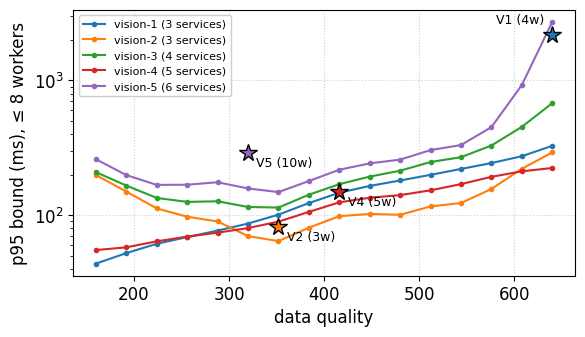

audio, 4 items/s
save_figure: c2_slo_plans_audio reaches beyond the figure by {'left': np.float64(0.04)} inches


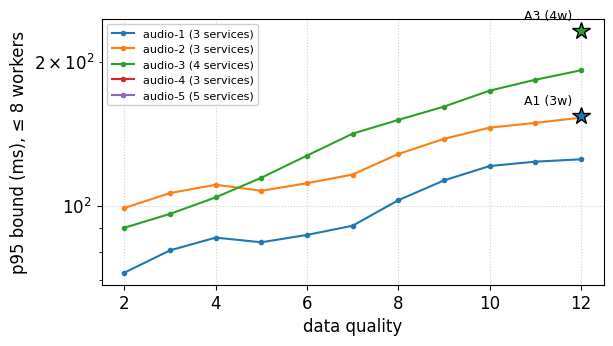

lidar, 20 items/s


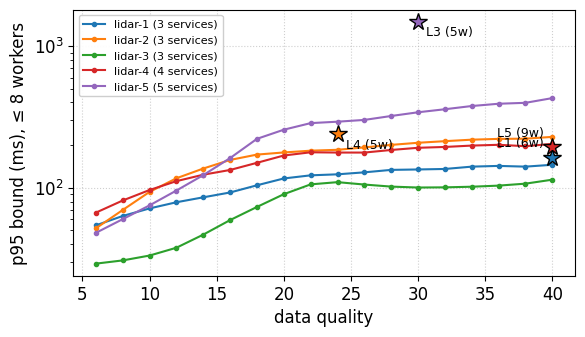

In [7]:
for app, comps in compositions.items():
    print(f"{app}, {ARRIVAL_RATE[app]:g} items/s")   # above the figure, not in it (no title in a paper figure)
    sp.tradeoff_figure(comps, plans_slsqp, SCENARIOS[app], app, WORKER_BUDGET, name=f"c2_slo_plans_{app}")

**Deployment table.** The SLSQP plan of every scenario in the knob names of the campaign (`shared.data_quality`,
`<node>.parallelism`, `<node>.model_size` in the column `knobs`), with the arrival rate to deploy it at and the
predicted bound; written to `statics/slo_planning/c2_plans.csv`.

In [8]:
deployment = sp.deployment_table(plans_slsqp, ARRIVAL_RATE)
sp.PLANS.mkdir(parents=True, exist_ok=True)
deployment.to_csv(sp.PLANS / "c2_plans.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(deployment.set_index(["application", "scenario"]))

arrival_rate  feasible   composition  \
application scenario                                                       
vision      V1 edge box                     15.0      True  b1u-vision-1   
            V2 interactive AR               15.0      True  b1u-vision-2   
            V3 forensic detail              15.0     False           NaN   
            V4 retail analytics             15.0      True  b1u-vision-4   
            V5 traffic monitoring           15.0      True  b1u-vision-5   
audio       A1 minimal footprint             4.0      True   b1u-audio-1   
            A2 voice assistant               4.0     False           NaN   
            A3 music archive                 4.0      True   b1u-audio-3   
            A4 live captions                 4.0     False           NaN   
            A5 conferencing                  4.0     False           NaN   
lidar       L1 embedded                     20.0      True   b1u-lidar-1   
            L2 collision avoidance          20.0     False           NaN   
            L3 HD mapping                   20.0      True   b1u-lidar-5   
            L4 fleet perception             20.0      True   b1u-lidar-2   
            L5 robotaxi                     20.0      True   b1u-lidar-4   

                                                                                  services  \
application scenario                                                                         
vision      V1 edge box                                detector → transformer → compressor   
            V2 interactive AR                                  faces → transformer → edges   
            V3 forensic detail                                                         NaN   
            V4 retail analytics            transformer → denoiser → motion → codes → edges   
            V5 traffic monitoring   motion → codes → detector → faces → edges → compressor   
audio       A1 minimal footprint                            resampler → cleaner → features   
            A2 voice assistant                                                         NaN   
            A3 music archive                           resampler → voice → pitch → encoder   
            A4 live captions                                                           NaN   
            A5 conferencing                                                            NaN   
lidar       L1 embedded                                   downsampler → ground → clusterer   
            L2 collision avoidance                                                     NaN   
            L3 HD mapping           downsampler → normals → registrar → clusterer → packer   
            L4 fleet perception                                  ground → normals → packer   
            L5 robotaxi                               ground → clusterer → viewer → packer   

                                    workers  predicted_p95_ms  \
application scenario                                            
vision      V1 edge box                 4.0            2177.5   
            V2 interactive AR           3.0              82.1   
            V3 forensic detail          NaN               NaN   
            V4 retail analytics         5.0             150.2   
            V5 traffic monitoring      10.0             291.3   
audio       A1 minimal footprint        3.0             154.5   
            A2 voice assistant          NaN               NaN   
            A3 music archive            4.0             232.5   
            A4 live captions            NaN               NaN   
            A5 conferencing             NaN               NaN   
lidar       L1 embedded                 6.0             162.3   
            L2 collision avoidance      NaN               NaN   
            L3 HD mapping               5.0            1483.4   
            L4 fleet perception         5.0             237.7   
            L5 robotaxi                 9.0             192.7   

                                      